# Our version: PWPAE + a drift-severity-aware response

**What this is.** The baseline notebooks in `baseline/` are the authors' PWPAE code and stay untouched as the control. This notebook is our version: the same four models, the same voting, the same data, with a layer added that reacts to a drift *in proportion to how big it is*.

| | What it adds | Needs labels? |
|---|---|---|
| **C1 severity-aware response** | When an alarm fires, measure how big the change is (score **S**) and react: small = nothing extra, medium = trust models by their recent record and re-teach them on recent flows, large = also replace the worst model | yes, instantly |
| **C1b boost learning** | After an alarm, learn every *new* flow several times for a while (2x for 500 flows at medium, 4x for 1,000 at high). Added after the first results showed that re-teaching old flows does little | yes, instantly |
| **C2 severity from uncertainty** | Same idea, but the alarm and score come from how unsure the models are, so no labels are needed | **no** |
| **C3 gated ensemble** | One cheap forest runs alone; the four-model ensemble is switched on only after an alarm | yes |
| **C4 fair evaluation** | 5-10 repeated runs, minority-aware metrics, dip depth and recovery time, paired differences with confidence intervals | - |

All code is in `ours/severity_pwpae.py`; this notebook runs it and shows the results.

In [1]:
import os, sys, json, inspect
os.chdir("..")                      # run from the repo root
sys.path.insert(0, "ours")
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display
import severity_pwpae as sp
import run_ext as rx
from analyse import full_metrics, rolling_mean
get_ipython().run_line_magic("matplotlib", "inline")   # analyse.py switches to a file-only backend; switch back so charts show here
DS = "CICIDS2017"
tuned = json.load(open("results/contrib/tuned.json"))
print("severity thresholds chosen on the validation stretch:", tuned)

severity thresholds chosen on the validation stretch: {'error_d0': [0.5, 2], 'uncertainty_d0': [0.5, 1.5], 'error_d200': [1, 3], 'uncertainty_d200': [1, 3]}


## The severity score

When the alarm fires we compare the models' mistake rate *now* with their mistake rate *just before*:

**S = |recent error − normal error| / (normal error + 0.01)**

`recent` = the last 100 flows, `normal` = the 300 flows before them. A big S means the old knowledge broke badly. The two thresholds turn S into low / medium / high.

In [2]:
print(inspect.getsource(sp.severity)); print(inspect.getsource(sp.level_of))

def severity(sig, recent, base, eps):
    """OURS. S = |recent - normal| / (normal + eps). None until enough history exists."""
    if len(sig) < recent + base // 2:
        return None
    a = np.asarray(sig[-recent:], float)
    b = np.asarray(sig[-(recent + base):-recent], float)
    return abs(a.mean() - b.mean()) / (b.mean() + eps)

def level_of(S, mode, tau):
    if mode == "uniform_medium":
        return "medium"
    if mode == "uniform_high":
        return "high"
    return "low" if S < tau[0] else ("medium" if S < tau[1] else "high")



## What happens at each level

| Level | Reaction (all inside the same loop that predicts and learns on every flow) |
|---|---|
| low | nothing extra |
| medium | for the next 1,000 flows judge each model only by its last 200 flows (fast trust), **and** re-teach every model on the last 200 labelled flows |
| high | the same, **and** replace the worst model by a fresh one trained on the last 500 flows |
| (C1b only) medium / high | additionally learn every new flow 2x for 500 flows / 4x for 1,000 flows |

A 200-flow cool-down stops one drift from triggering several reactions.

In [3]:
print(inspect.getsource(sp.run)[:200]); print('...'); print(inspect.getsource(sp.run)[inspect.getsource(sp.run).index('# ----------------'):][:1700])

def run(ds, seed, n_stop=None, **over):
    c = {**CFG, **over}
    tr, ytr, te, yte, _ = rx.load(ds)
    if n_stop:
        te, yte = te[:n_stop], yte[:n_stop]
    models = [rx.make_base(k, seed) for
...
# ---------------- OURS: severity-scaled reaction
            sig = EE[:nrev] if c["signal"] == "error" else u_hist
            S = severity(sig, c["recent"], c["base"], c["eps_s"])
            if S is not None:
                lvl = level_of(S, c["level_mode"], c["tau"])
                last_react = i
                events.append((i, round(float(S), 3), lvl))
                if lvl != "low":
                    if c["act_weights"]:
                        fast_until = i + c["hold"]
                    if c["act_boost"]:
                        j = 1 if lvl == "high" else 0
                        boost_until, boost_n = i + c["boost_hold"][j], c["boost_k"][j]
                    if c["act_replay"]:
                        for xx, yy in list(buf)[-c["replay"]:]:
                      

## Run the baseline and our version on the same stream (one seed, full CICIDS2017 test stream, a few minutes)

In [4]:
START = int(0.30 * 25473)          # first 30 % = tuning stretch; all scores below use the rest
tr, ytr, te, yte, dr = rx.load(DS)
base = sp.run(DS, 1)
ours = sp.run(DS, 1, signal="error", tau=tuple(tuned["error_d0"]))                     # C1: severity-scaled
boost = sp.run(DS, 1, signal="error", level_mode="uniform_high", act_boost=True)      # C1b: always react hard + boost new flows
drs = [d - START for d in dr if d > START + 300]
for name, r in [("baseline", base), ("C1 severity", ours), ("C1b boost", boost)]:
    m = full_metrics(r["y"][START:], r["pred"][START:], r["p1"][START:], r["lat"][START:], drs, int(r["y"][START - 1]))
    print(f"{name:10s} accuracy {m['acc']*100:.2f}%  macro-F1 {m['macro_f1']*100:.2f}  MCC {m['mcc']:.3f}  worst 500-flow window {m['worst_acc_w500']*100:.1f}%  "
          f"dip {m['drop']*100:.1f} pts  recovery {m['recovery']:.0f} flows  latency {m['lat_ms']:.1f} ms (this live demo shares the CPU, so timings here are rough; clean timings are in the tables below)")
print("C1 reactions:", ours["events"], "| models replaced:", ours["replaced"])
print("C1b reactions:", boost["events"], "| models replaced:", boost["replaced"])

baseline   accuracy 99.05%  macro-F1 98.15  MCC 0.963  worst 500-flow window 93.8%  dip 7.9 pts  recovery 227 flows  latency 4.3 ms (this live demo shares the CPU, so timings here are rough; clean timings are in the tables below)
C1 severity accuracy 99.02%  macro-F1 98.08  MCC 0.962  worst 500-flow window 95.4%  dip 6.8 pts  recovery 252 flows  latency 4.4 ms (this live demo shares the CPU, so timings here are rough; clean timings are in the tables below)
C1b boost  accuracy 99.10%  macro-F1 98.25  MCC 0.965  worst 500-flow window 95.0%  dip 8.2 pts  recovery 177 flows  latency 5.6 ms (this live demo shares the CPU, so timings here are rough; clean timings are in the tables below)
C1 reactions: [(3492, 0.2, 'low'), (14246, 8.0, 'high'), (17943, 0.0, 'low'), (19360, 0.0, 'low'), (21875, 1.25, 'medium'), (25153, 1.5, 'medium')] | models replaced: 1
C1b reactions: [(3492, 0.2, 'high'), (14589, 0.647, 'high'), (17611, 0.1, 'high'), (19255, 0.429, 'high'), (21705, 5.5, 'high')] | models re

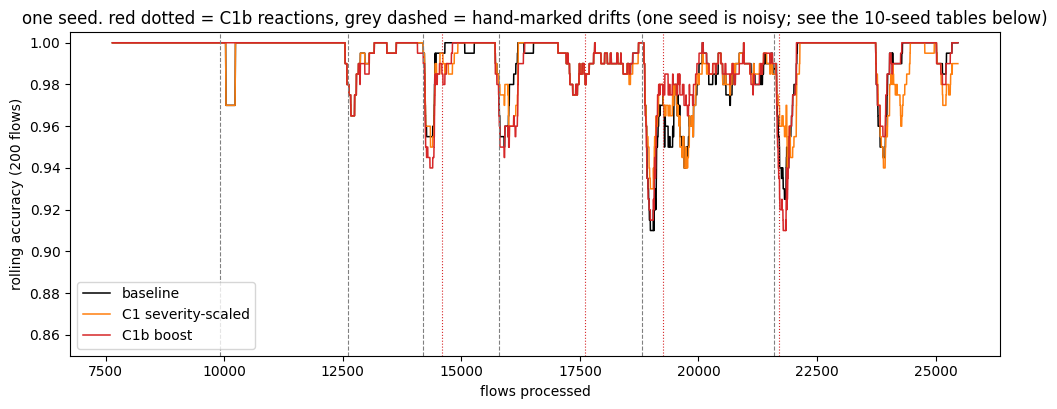

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.2))
for r, c, nm in [(base, "k", "baseline"), (ours, "tab:orange", "C1 severity-scaled"), (boost, "tab:red", "C1b boost")]:
    ra = rolling_mean((r["pred"] == r["y"]).astype(float), 200)[START:]
    ax.plot(np.arange(START, START + len(ra)), ra, c, lw=1.1, label=nm)
col = {"low": "tab:green", "medium": "tab:orange", "high": "tab:red"}
for i, S, l in boost["events"]:
    if i >= START: ax.axvline(i, color="tab:red", ls=":", lw=.8)
for g in dr:
    if g >= START: ax.axvline(g, color="grey", ls="--", lw=.8)
ax.set_ylim(0.85, 1.005); ax.set_xlabel("flows processed"); ax.set_ylabel("rolling accuracy (200 flows)"); ax.legend(loc="lower left")
ax.set_title("one seed. red dotted = C1b reactions, grey dashed = hand-marked drifts (one seed is noisy; see the 10-seed tables below)"); plt.show()

## Impact over repeated runs (paired differences to the baseline; `*` = clearly not zero)

In [6]:
s = open("results/contrib_summary.md", encoding="utf8").read()
display(Markdown(s.split("\n## ")[1] if "\n## " in s else s))

CICIDS2017

### Contributions 1-3 (labels arrive instantly)

| variant | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr | alarms | replaced | ensemble-on |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Baseline PWPAE | 98.99±0.07 | 98.02±0.14 | 0.961±0.003 | 0.772±0.016 | 94.28±0.90 | 7.98±0.69 | 243.77±32.79 | 11.89±0.98 | 84.54±6.47 | 0.0 | 0.0 | - |
| C1 severity-aware (labels) | 99.01±0.06 | 98.06±0.12 | 0.961±0.002 | 0.775±0.013 | 94.36±0.79 | 7.32±0.51 | 249.10±20.46 | 12.07±1.13 | 83.39±7.62 | 5.8 | 1.4 | - |
| C2 severity from uncertainty (no labels) | 98.97±0.03 | 97.98±0.06 | 0.960±0.001 | 0.767±0.006 | 94.44±0.62 | 8.28±0.72 | 264.10±31.04 | 12.34±1.45 | 81.89±8.81 | 18.8 | 0.8 | - |
| ablation: always 'medium' | 99.00±0.05 | 98.04±0.10 | 0.961±0.002 | 0.774±0.011 | 94.28±0.36 | 7.31±0.73 | 226.73±41.06 | 11.40±1.83 | 90.00±18.12 | 5.2 | 0.0 | - |
| ablation: always 'high' | 99.03±0.08 | 98.10±0.15 | 0.962±0.003 | 0.781±0.017 | 94.64±1.11 | 6.89±0.50 | 209.43±41.12 | 11.71±1.28 | 86.32±10.64 | 5.6 | 5.6 | - |
| ablation: fast-trust only | 98.99±0.06 | 98.02±0.13 | 0.960±0.003 | 0.771±0.015 | 94.48±0.61 | 7.88±0.54 | 231.10±15.03 | 10.95±1.16 | 92.26±11.07 | 5.6 | 0.0 | - |
| ablation: fast-trust + re-teach | 99.00±0.06 | 98.04±0.11 | 0.961±0.002 | 0.773±0.013 | 94.32±0.11 | 7.32±0.76 | 233.60±33.75 | 11.29±1.07 | 89.33±9.48 | 5.8 | 0.0 | - |
| single 10-tree forest | 98.92±0.04 | 97.88±0.09 | 0.958±0.002 | 0.756±0.010 | 92.24±0.91 | 9.04±0.70 | 246.93±42.40 | 3.68±0.38 | 273.98±26.07 | 0.0 | 0.0 | - |
| C3 gated ensemble | 98.99±0.06 | 98.01±0.12 | 0.960±0.002 | 0.771±0.014 | 93.52±0.70 | 7.71±0.55 | 221.07±27.29 | 7.53±0.85 | 134.09±14.93 | 5.6 | 0.0 | 16% |


**Paired difference to the baseline** (positive = higher; for `drop`, `recovery`, `lat_ms` lower is better)

| vs **Baseline PWPAE** | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr |
|---|---|---|---|---|---|---|---|---|---|
| C1 severity-aware (labels) | +0.02 ±0.09 | +0.03 ±0.17 | +0.00 ±0.00 | +0.00 ±0.02 | +0.08 ±1.34 | -0.66 ±1.17 | +5.33 ±32.68 | +0.19 ±0.54 | -1.15 ±4.23 |
| C2 severity from uncertainty (no labels) | -0.02 ±0.07 | -0.04 ±0.15 | -0.00 ±0.00 | -0.00 ±0.02 | +0.16 ±1.36 | +0.30 ±1.47 | +20.33 ±34.15 | +0.45 ±0.96 | -2.66 ±6.37 |
| ablation: always 'medium' | +0.01 ±0.11 | +0.02 ±0.21 | +0.00 ±0.00 | +0.00 ±0.02 | -0.00 ±1.29 | -0.67 ±1.27 | -17.03 ±40.46 | -0.48 ±3.39 | +5.46 ±29.84 |
| ablation: always 'high' | +0.04 ±0.07 | +0.08 ±0.14 | +0.00 ±0.00 | +0.01 ±0.02 | +0.36 ±1.87 | -1.09 ±1.34 | -34.33 ±78.09 | -0.18 ±2.66 | +1.78 ±20.27 |
| ablation: fast-trust only | -0.00 ±0.02 | -0.00 ±0.04 | -0.00 ±0.00 | -0.00 ±0.00 | +0.20 ±0.56 | -0.10 ±0.31 | -12.67 ±34.59 | -0.94 ±2.53 | +7.72 ±20.91 |
| ablation: fast-trust + re-teach | +0.01 ±0.12 | +0.02 ±0.23 | +0.00 ±0.00 | +0.00 ±0.03 | +0.04 ±1.16 | -0.66 ±1.44 | -10.17 ±57.18 | -0.60 ±2.50 | +4.78 ±19.43 |
| single 10-tree forest | -0.07 ±0.12 | -0.14 ±0.24 | -0.00 ±0.00 | -0.02 ±0.03 | -2.04 ±1.17 * | +1.07 ±1.42 | +3.17 ±73.93 | -8.21 ±0.83 * | +189.44 ±26.00 * |
| C3 gated ensemble | -0.00 ±0.14 | -0.01 ±0.28 | -0.00 ±0.01 | -0.00 ±0.03 | -0.76 ±1.14 | -0.27 ±1.12 | -22.70 ±37.66 | -4.35 ±0.99 * | +49.55 ±15.28 * |


**Does scaling the reaction by severity matter?** (C1 vs. the same reaction applied to every alarm)

| vs **C1 severity-aware (labels)** | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr |
|---|---|---|---|---|---|---|---|---|---|
| ablation: always 'medium' | -0.01 ±0.12 | -0.02 ±0.24 | -0.00 ±0.00 | -0.00 ±0.03 | -0.08 ±1.12 | -0.01 ±0.38 | -22.37 ±52.76 | -0.67 ±3.52 | +6.61 ±30.53 |
| ablation: always 'high' | +0.02 ±0.10 | +0.05 ±0.19 | +0.00 ±0.00 | +0.01 ±0.02 | +0.28 ±1.45 | -0.43 ±0.61 | -39.67 ±63.51 | -0.36 ±2.79 | +2.93 ±21.04 |


### Contribution 2: labels arrive 200 flows late

| variant | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr | alarms | replaced | ensemble-on |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Baseline PWPAE | 98.99±0.07 | 98.02±0.14 | 0.961±0.003 | 0.772±0.016 | 94.28±0.90 | 7.98±0.69 | 243.77±32.79 | 11.89±0.98 | 84.54±6.47 | 0.0 | 0.0 | - |
| Baseline, labels 200 late | 97.01±0.03 | 93.90±0.08 | 0.880±0.001 | 0.324±0.008 | 52.56±2.94 | 26.81±0.62 | 456.27±11.37 | 11.48±0.32 | 87.15±2.40 | 0.0 | 0.0 | - |
| C1, labels 200 late | 97.06±0.08 | 93.99±0.17 | 0.882±0.003 | 0.335±0.017 | 52.00±1.28 | 26.48±0.28 | 409.90±20.53 | 11.86±0.42 | 84.40±3.01 | 5.8 | 2.4 | - |
| C2, labels 200 late | 97.07±0.07 | 93.99±0.15 | 0.882±0.003 | 0.336±0.015 | 51.00±2.16 | 26.23±0.32 | 436.43±16.35 | 11.59±0.47 | 86.39±3.49 | 25.8 | 2.0 | - |


**Paired difference to the baseline under the same delay**

| vs **Baseline, labels 200 late** | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr |
|---|---|---|---|---|---|---|---|---|---|
| C1, labels 200 late | +0.05 ±0.12 | +0.09 ±0.26 | +0.00 ±0.00 | +0.01 ±0.03 | -0.56 ±3.71 | -0.33 ±0.96 | -46.37 ±17.70 * | +0.38 ±0.68 | -2.74 ±4.99 |
| C2, labels 200 late | +0.06 ±0.08 | +0.09 ±0.18 | +0.00 ±0.00 | +0.01 ±0.02 | -1.56 ±2.62 | -0.58 ±1.08 | -19.83 ±22.92 | +0.11 ±0.64 | -0.76 ±4.77 |


**Cost of the delay on the baseline itself**

| vs **Baseline PWPAE** | acc | macro_f1 | mcc | kappa_t | worst_acc_w500 | drop | recovery | lat_ms | thr |
|---|---|---|---|---|---|---|---|---|---|
| Baseline, labels 200 late | -1.98 ±0.12 * | -4.12 ±0.24 * | -0.08 ±0.00 * | -0.45 ±0.03 * | -41.72 ±3.58 * | +18.83 ±1.25 * | +212.50 ±28.55 * | -0.41 ±1.31 | +2.60 ±8.66 |


**Contribution 3, accuracy side:** the ensemble's gain over the single forest is small to begin with (MCC 0.958 -> 0.961, macro-F1 97.88 -> 98.02); the gated ensemble sits at MCC 0.960 / macro-F1 98.01. Its worst 500-flow window is the clearest difference (see table).


**Contribution 3, cost side (clean timing: one run at a time on an idle machine, seed 1; the table latencies above come from runs that shared the CPU)**

| variant | mean ms/flow | p99 ms/flow | flows/second |
|---|---|---|---|
| Baseline PWPAE | 1.88 | 3.17 | 531 |
| C1 severity-aware | 1.90 | 3.14 | 528 |
| C1b always-react + boost | 2.82 | 8.60 | 355 |
| single 10-tree forest | 0.57 | 1.28 | 1747 |
| C3 gated ensemble | 1.06 | 3.22 | 940 |



In [7]:
display(Markdown(open("results/contrib_followup.md", encoding="utf8").read()))

# Follow-up results (collected from ours/more_seeds.py report and ours/confirm.py report)

The first round (`contrib_summary.md`) showed that the severity-scaled reaction C1 changed nothing measurable, and that replaying old flows does little because the models already learn every flow. So we added a reaction that **boosts learning on the new flows** after an alarm (`act_boost`: medium = each new flow learned 2x for 500 flows, high = 4x for 1,000 flows) and compared on 10 seeds (CICIDS2017, scored on the last 70 % of the stream).

Variants: `C1` = severity-scaled, old reaction | `C1_uniform_high` = old reaction at maximum strength on every alarm | `C1b_boost` = severity-scaled, with boost | `C1b_uniform_high` = maximum reaction + boost on every alarm | `C1b_boost_only` = only the boost | `C1b_boost_fasttrust` = boost + fast-trust weights.
Caution: `C1b_uniform_high` was picked *after* seeing these ten seeds, so it is confirmed again on fresh seeds below.

## Seeds 1-10, paired difference to the baseline
```
paired difference to the baseline over 10 seeds (mean ±95% CI; * = excludes 0). Positive = higher.

C1
  acc             -0.001 ±0.049   (seeds better: 3/10)
  macro_f1        -0.002 ±0.097   (seeds better: 3/10)
  mcc             -0.000 ±0.002   (seeds better: 3/10)
  worst_acc_w500  +0.140 ±0.661   (seeds better: 5/10)
  drop            -0.328 ±0.599   (seeds better: 5/10)
  recovery        -7.850 ±25.218   (seeds better: 6/10)

C1_uniform_high
  acc             +0.014 ±0.045   (seeds better: 6/10)
  macro_f1        +0.027 ±0.089   (seeds better: 6/10)
  mcc             +0.001 ±0.002   (seeds better: 6/10)
  worst_acc_w500  +0.360 ±0.817   (seeds better: 4/10)
  drop            -0.483 ±0.784   (seeds better: 5/10)
  recovery        -31.483 ±41.814   (seeds better: 6/10)

C1b_boost
  acc             +0.029 ±0.032   (seeds better: 6/10)
  macro_f1        +0.055 ±0.064   (seeds better: 6/10)
  mcc             +0.001 ±0.001   (seeds better: 6/10)
  worst_acc_w500  +0.620 ±0.488 *   (seeds better: 7/10)
  drop            -0.256 ±0.559   (seeds better: 7/10)
  recovery        -39.533 ±34.461 *   (seeds better: 6/10)

C1b_uniform_high
  acc             +0.107 ±0.071 *   (seeds better: 8/10)
  macro_f1        +0.212 ±0.141 *   (seeds better: 8/10)
  mcc             +0.004 ±0.003 *   (seeds better: 8/10)
  worst_acc_w500  +1.100 ±0.630 *   (seeds better: 8/10)
  drop            -0.661 ±0.770   (seeds better: 7/10)
  recovery        -62.683 ±41.327 *   (seeds better: 9/10)

C1b_boost_only
  acc             +0.070 ±0.060 *   (seeds better: 8/10)
  macro_f1        +0.138 ±0.118 *   (seeds better: 8/10)
  mcc             +0.003 ±0.002 *   (seeds better: 8/10)
  worst_acc_w500  +1.000 ±0.815 *   (seeds better: 7/10)
  drop            -0.572 ±0.733   (seeds better: 8/10)
  recovery        -35.783 ±29.051 *   (seeds better: 8/10)

C1b_boost_fasttrust
  acc             +0.079 ±0.065 *   (seeds better: 9/10)
  macro_f1        +0.154 ±0.128 *   (seeds better: 9/10)
  mcc             +0.003 ±0.003 *   (seeds better: 9/10)
  worst_acc_w500  +1.080 ±0.942 *   (seeds better: 6/10)
  drop            -0.600 ±0.971   (seeds better: 7/10)
  recovery        -29.400 ±54.996   (seeds better: 7/10)
B0 recovery mean 250 ± 37
C1 recovery mean 242 ± 32
C1_uniform_high recovery mean 218 ± 39
C1b_boost recovery mean 210 ± 34
C1b_uniform_high recovery mean 187 ± 33
C1b_boost_only recovery mean 214 ± 29
C1b_boost_fasttrust recovery mean 220 ± 50
```

## Confirmation on fresh seeds (21-30), no-harm check on IoTID20, and labels 200 flows late
```

CICIDS2017, fresh seeds 21-30: always-react-hard + boost  vs  baseline  (n=10 paired seeds; mean difference ±95% CI, * = excludes 0)
  acc             +0.075 ±0.052 *   better in 9/10 seeds
  macro_f1        +0.147 ±0.101 *   better in 9/10 seeds
  mcc             +0.003 ±0.002 *   better in 9/10 seeds
  worst_acc_w500  +0.700 ±0.743   better in 9/10 seeds
  drop            -0.433 ±0.725   better in 7/10 seeds
  recovery        -61.783 ±38.584 *   better in 9/10 seeds

IoTID20, seeds 1-3: same variant vs baseline  (n=3 paired seeds; mean difference ±95% CI, * = excludes 0)
  acc             +0.042 ±0.298   better in 1/3 seeds
  macro_f1        +0.250 ±1.630   better in 1/3 seeds
  mcc             +0.004 ±0.031   better in 1/3 seeds
  worst_acc_w500  +0.200 ±1.791   better in 1/3 seeds
  drop            +nan ±nan   better in 3/3 seeds
  recovery        +nan ±nan   better in 3/3 seeds

CICIDS2017, labels 200 flows late, seeds 1-5: same variant vs baseline with the same delay  (n=5 paired seeds; mean difference ±95% CI, * = excludes 0)
  acc             +0.224 ±0.067 *   better in 5/5 seeds
  macro_f1        +0.480 ±0.138 *   better in 5/5 seeds
  mcc             +0.009 ±0.003 *   better in 5/5 seeds
  worst_acc_w500  +6.280 ±3.715 *   better in 5/5 seeds
  drop            -0.644 ±3.391   better in 2/5 seeds
  recovery        -28.833 ±45.898   better in 4/5 seeds
```


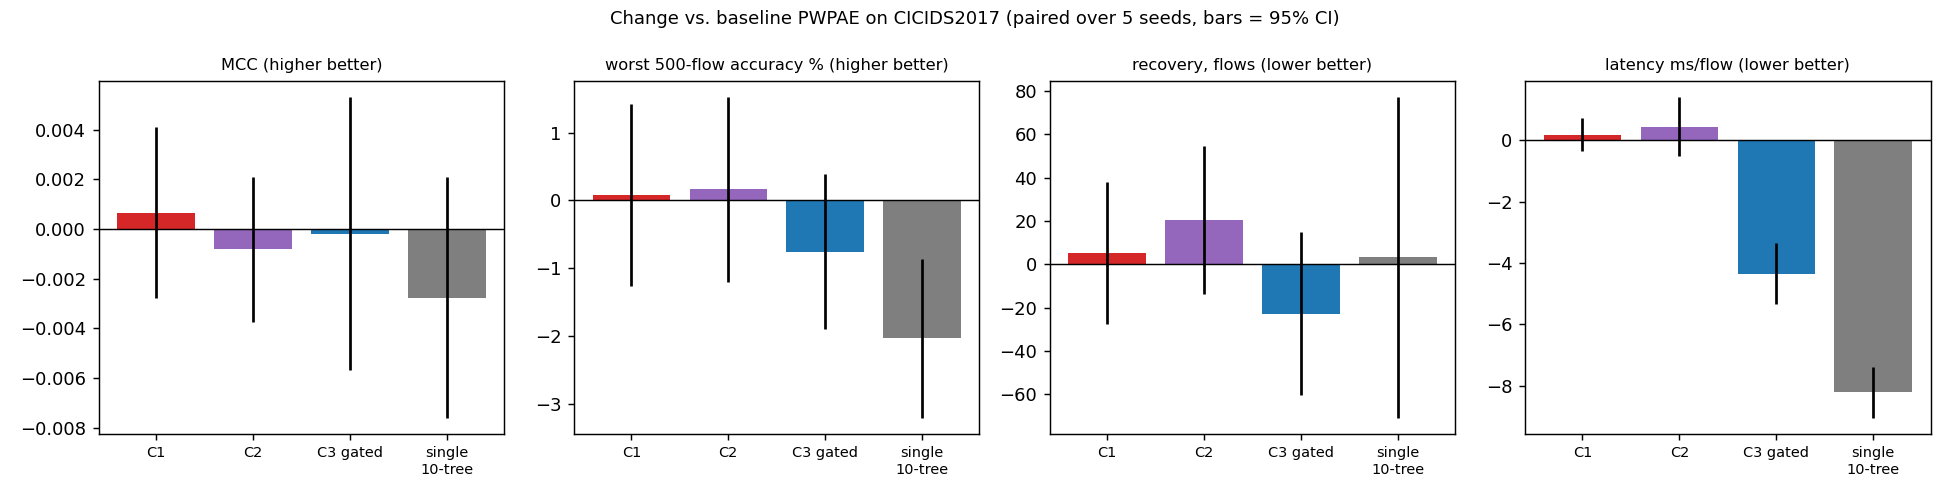

In [8]:
display(Image("results/fig_contrib_impact.png"))

# Record of each contribution: process, observations, conclusion

**How every comparison was run (same for all contributions).** Same four models, voting rule and data as the baseline. CICIDS2017 is the only stream with real drift, so it carries the verdicts; IoTID20 is a no-harm check. The first 10 % of each stream is warm-up training; the first 30 % of the test stream is a tuning stretch (thresholds tuned there, with seeds never used for scoring); everything is **scored on the last 70 %**. Each variant is run on the same seeds as the baseline (5 seeds for the main comparison, 10 for the follow-up, 10 *fresh* seeds for confirmation) and compared **pair-by-pair**: *mean difference ± 95 % confidence interval*; a difference only counts when the interval excludes zero. Speed numbers come from one run at a time on an idle machine. Drift points are hand-marked by the original authors, so "recovery" = flows until accuracy is back within 1 point of its pre-drift level.

## C1: severity-scaled reaction  ->  does **not** improve the baseline
**Process.** A drift alarm (EDDM on the ensemble's error) triggers a score S = |recent error − normal error| / (normal error + 0.01). Two thresholds turn S into low / medium / high; medium re-teaches the models on the last 200 flows and trusts them by their last 200 flows, high also replaces the worst model with a fresh one. Thresholds were picked from a small grid on the tuning stretch.
**Observations (10 seeds).** Accuracy −0.001 ± 0.049, macro-F1 −0.002 ± 0.097, MCC −0.000 ± 0.002, recovery −8 ± 25 flows: nothing measurable. Applying the same reaction at full strength on *every* alarm was not worse (recovery −31 ± 42), so scaling by severity added nothing. All variants scored the same on the tuning stretch, so the chosen thresholds are essentially arbitrary.
**Conclusion.** The severity-scaling idea is not supported here. Likely reason: the models already learn every flow, so re-teaching them on flows they just saw is mostly redundant.

## C1b: boost learning on new flows after an alarm  ->  **improves** recovery, at a cost
**Process.** Added after C1 failed: after an alarm, every *new* labelled flow is learned several times for a while (2x for 500 flows at medium, 4x for 1,000 at high), optionally with the C1 reactions. The strongest variant (react at full strength on every alarm, with boost) was chosen after seeing seeds 1-10, so it was **re-tested on 10 fresh seeds**. An ablation separated the parts.
**Observations.** Seeds 1-10: accuracy +0.107 ± 0.071, macro-F1 +0.21 ± 0.14, MCC +0.004 ± 0.003, recovery **−63 ± 41 flows** (250 → 187). Fresh seeds 21-30: accuracy +0.075 ± 0.052, macro-F1 +0.15 ± 0.10, MCC +0.003 ± 0.002, recovery −62 ± 39 flows, better in 9 of 10 seeds (the dip depth and worst-stretch accuracy moved the right way but not beyond noise). Ablation: the boost alone gives about half (accuracy +0.07, recovery −36 ± 29); replacing the worst model and re-teaching add the rest. Cost: mean time per flow 1.88 → 2.82 ms, worst case (p99) 3.2 → 8.6 ms. IoTID20: no alarms fire, so it is identical to the baseline (no harm).
**Conclusion.** A small but repeatable improvement: about 25 % faster recovery and slightly higher accuracy/F1, paid for with extra learning time right after each alarm. Gains are small in absolute terms because the baseline is already about 99 % accurate.

## C2: severity from model uncertainty (no labels needed)  ->  does **not** improve the baseline
**Process.** Same reaction as C1, but the alarm (ADWIN) and the score S come from the models' own uncertainty min(p, 1−p), which needs no labels. Motivation: uncertainty tracked the error well (correlation 0.76 on CICIDS2017, 0.66 on IoTID20).
**Observations.** About 19 alarms per run versus 6 for C1, mostly not followed by a real error burst. Accuracy −0.02 ± 0.07 and recovery +20 ± 34 flows (not better); with labels 200 flows late, recovery −20 ± 23 (not significant). Feeding raw input-feature drift alarms into the same idea was also tested offline: alarms were followed by an error burst 54 % of the time, the same as a random point.
**Conclusion.** Uncertainty tracks error on average but is too noisy as an alarm. Not an improvement.

## C3: gated ensemble (one cheap forest, ensemble only after an alarm)  ->  **same accuracy at about half the cost**
**Process.** A single 10-tree forest runs alone. An error alarm wakes the other three models, trained on the last 1,000 labelled flows; the four vote for 600 flows; then the extra three are dropped. Motivation: the four-model ensemble costs about 3x one forest, and the four models disagree on only 1-2 % of flows.
**Observations (5 seeds, CICIDS2017).** Accuracy −0.00 ± 0.14, macro-F1 −0.01 ± 0.28, MCC −0.00 ± 0.01 versus the always-on ensemble: indistinguishable. Worst 500-flow stretch −0.8 ± 1.1 (not significant). The ensemble was on for 16 % of flows. Clean timing: **1.06 ms vs 1.88 ms per flow, 940 vs 531 flows/s**, same p99 (3.2 ms). The single forest alone is cheapest (0.57 ms) but its worst stretch is clearly worse (−2.0 ± 1.2 points). IoTID20: −0.31 ± 0.49 accuracy, inconclusive.
**Conclusion.** Not an accuracy improvement; a **cost improvement**: roughly 44 % less time per flow with no measurable accuracy loss on the stream that drifts.

## Label delay (labels arrive 200 flows late)  ->  the baseline's biggest weakness; only partly fixed
**Process.** Each flow's label is revealed 200 flows after its prediction; models learn and errors are measured with that delay. Baseline compared with itself undelayed, then C1 / C1b / C2 compared with the baseline under the same delay (5 seeds).
**Observations.** The delay alone costs the baseline accuracy −1.98 ± 0.12, macro-F1 −4.1, and its worst 500-flow stretch falls from **94 % to 53 %**; recovery goes from 244 to 456 flows. Under delay, C1 recovers 46 ± 18 flows sooner and the boosted variant adds accuracy +0.22 ± 0.07, MCC +0.009 ± 0.003 and worst stretch +6.3 ± 3.7 points; C2 gives nothing. Most of the damage remains.
**Conclusion.** Not an improvement but an important finding: assuming instant labels flatters the baseline. Our reactions soften the damage only slightly; a real fix would need a method that learns without waiting for labels.

## C4: fair evaluation protocol  ->  methodology, changes how results are read
**Process.** Repeated seeds, paired differences with confidence intervals, minority-aware metrics (macro-F1, MCC, false-positive/negative rates), windowed accuracy, dip depth and recovery time, a separate tuning stretch, fresh-seed confirmation, clean timing.
**Observations.** Run-to-run noise is as large as the claimed gaps between methods in the original papers (accuracy std 0.2-0.6 points between identical runs). With 5 seeds a recovery change smaller than about 35-40 flows cannot be detected, which is why C1b needed 10 and 10 more seeds.
**Conclusion.** Not a model change. It is what makes the verdicts above trustworthy, and it showed that C1 and C2 have no effect rather than a hidden one.

## Earlier explorations (kept out of our version)  ->  none improved the baseline
| Tried | Observation | Verdict |
|---|---|---|
| Resampling (random over/under, over/under-bagging, sliding-window bagging, SMOTE-style), 9 strategies | Higher minority recall and balanced accuracy, but lower macro-F1/MCC, worse calibration, more latency; none beat no sampling | No |
| Other weighting windows for the vote (fixed, fading, reset at alarm, leader-takes-all, softmax) | Best was +0.1 point macro-F1 on one stream, not reliable; plain averaging scored the same as the baseline's weighting (99.142 vs 99.144) | No |
| Decision threshold other than 0.5 | 0.5 is already near-optimal | No |
| Oracle bound on any re-weighting | At most about 0.5 point of accuracy, because the four models rarely disagree | Explains why re-weighting cannot help much |

## Overall: does our version improve the baseline?
| Contribution | Improves the baseline? | Size of effect |
|---|---|---|
| C1 severity-scaled reaction | **No** | none measurable |
| C1b boost learning on new flows | **Yes, modestly** | recovery about 62 flows faster (about 25 %), accuracy +0.075, macro-F1 +0.15; extra time after each alarm |
| C2 severity from uncertainty | **No** | none; too many false alarms |
| C3 gated ensemble | **Cost only** | same accuracy, about 44 % less time per flow |
| Label-delay test | n/a (a weakness found) | worst stretch 94 % -> 53 % for the baseline; reactions help a little |
| C4 evaluation protocol | n/a (method) | makes the above trustworthy |

**Limits.** Only CICIDS2017 has drift (IoTID20 never triggers a reaction); the drift points are hand-marked; thresholds were tuned on a stretch where every variant scored the same; all timings are from one CPU. The combination of C1b and C3 has not been tested together.